In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Fix path resolution to point to project root
PROJECT_ROOT = Path(os.getcwd()).parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

# Import your custom architecture components
from src.morphology.query_analyzer import QueryAnalyzer
from src.utils.io import load_jsonl, save_json
from src.utils.helpers import print_section

print(f"📦 Workspace initialized. Project Root: {PROJECT_ROOT}")

📦 Workspace initialized. Project Root: d:\inu\QA_FINTECH_FINAL


In [2]:
# Define systematic test queries representing varied Amharic FinTech structural densities
sample_queries = [
    {"query": "ቴሌብር ምንድን ነው?", "expected_type": "definition"},
    {"query": "ትርጉም ስጥ ለ ሞባይል ባንኪንግ።", "expected_type": "definition"},
    {"query": "በቴሌብር አካውንት እንዴት መክፈት እችላለሁ?", "expected_type": "procedure"},
    {"query": "ወደ ሌላ ሰው ሂሳብ ገንዘብ ለማስተላለፍ ምን ማድረግ አለብኝ?", "expected_type": "procedure"},
    {"query": "ሲስተሙ አልሰራም አለኝ፣ error ኮድ 403 እያሳየ ነው ምን ላድርግ?", "expected_type": "troubleshooting"},
    {"query": "የአገልግሎት ክፍያ ገደብ እና የባንክ ወለድ መጠን ስንት ነው?", "expected_type": "policy_fee"},
    {"query": "በየቀኑ ማስተላለፍ የምችለው ከፍተኛ የገንዘብ መጠን ስንት ነው?", "expected_type": "policy_fee"},
    {"query": "ትላንትና የተላከልኝን አጭር የጽሑፍ መልዕክት አላገኘሁትም", "expected_type": "general_fintech"},
]

print(f"Loaded {len(sample_queries)} baseline benchmarking queries.")

Loaded 8 baseline benchmarking queries.


In [3]:
import pandas as pd

results = []

# 1. Initialize the analyzer ONCE outside the loop
analyzer = QueryAnalyzer()  

for item in sample_queries:
    q_text = item["query"]
    
    # 2. Call the analyze method passing the query string correctly
    analysis = analyzer.analyze(q_text)
    
    # Safely unpack the inner feature and complexity dictionaries
    features = analysis["features"]
    complexity = analysis["complexity"]
    
    # 3. Flatten dictionary fields using the exact keys present in your components
    flattened_entry = {
        "query": q_text,
        "expected_type": item.get("expected_type", "N/A"),
        "predicted_label": complexity.get("complexity_label", "low"),  # from your class label assignment
        "num_tokens": features.get("token_count", 0),
        "avg_token_length": round(features.get("avg_token_length", 0.0), 2),
        "suffix_hits": features.get("suffix_match_total", 0),
        "complexity_score": complexity.get("complexity_score", 0.0),
        "retrieval_hint": complexity.get("retrieval_hint", "hybrid")
    }
    results.append(flattened_entry)

# Convert to DataFrame for analytical manipulation
df_morphology = pd.DataFrame(results)
df_morphology

,query,expected_type,predicted_label,num_tokens,avg_token_length,suffix_hits,complexity_score,retrieval_hint
0,ቴሌብር ምንድን ነው?,definition,low,3,3.67,1,0.2235,sparse_or_hybrid_light
1,ትርጉም ስጥ ለ ሞባይል ባንኪንግ።,definition,low,5,3.40,1,0.2156,sparse_or_hybrid_light
2,በቴሌብር አካውንት እንዴት መክፈት እችላለሁ?,procedure,low,5,4.80,0,0.2322,sparse_or_hybrid_light
3,ወደ ሌላ ሰው ሂሳብ ገንዘብ ለማስተላለፍ ምን ማድረግ አለብኝ?,procedure,low,9,3.44,2,0.3115,sparse_or_hybrid_light
4,ሲስተሙ አልሰራም አለኝ፣ error ኮድ 403 እያሳየ ነው ምን ላድርግ?,troubleshooting,medium,10,3.60,4,0.3879,hybrid
5,የአገልግሎት ክፍያ ገደብ እና የባንክ ወለድ መጠን ስንት ነው?,policy_fee,medium,9,3.44,1,0.3307,hybrid
6,በየቀኑ ማስተላለፍ የምችለው ከፍተኛ የገንዘብ መጠን ስንት ነው?,policy_fee,low,8,4.12,2,0.3079,sparse_or_hybrid_light
7,ትላንትና የተላከልኝን አጭር የጽሑፍ መልዕክት አላገኘሁትም,general_fintech,low,6,5.17,2,0.2947,sparse_or_hybrid_light


In [4]:
import pandas as pd
from src.morphology.query_analyzer import QueryAnalyzer

# 1. Define the functional wrapper expected by the loop
def analyze_query(query_text: str) -> dict:
    """Initializes the QueryAnalyzer framework and processes text."""
    analyzer = QueryAnalyzer()
    return analyzer.analyze(query_text)

results = []

# 2. Iterate through your testing corpus evaluation matrix
for item in sample_queries:
    q_text = item["query"]
    
    # Executing the function wrapper directly
    analysis = analyze_query(q_text)
    
    # Safely extract core metrics dictionaries
    features = analysis.get("features", {})
    complexity = analysis.get("complexity", {})
    
    # Flatten processing artifacts using explicit baseline metrics
    flattened_entry = {
        "query": q_text,
        "expected_type": item.get("expected_type", "N/A"),
        "predicted_label": complexity.get("complexity_label", "low"),  
        "num_tokens": features.get("token_count", 0),                 
        "avg_token_length": round(features.get("avg_token_length", 0.0), 2),
        "suffix_hits": features.get("suffix_match_total", 0),          
        "complexity_score": complexity.get("complexity_score", 0.0),
        "retrieval_hint": complexity.get("retrieval_hint", "hybrid")
    }
    results.append(flattened_entry)

# 3. Render analytical outputs inside your pandas framework
df_morphology = pd.DataFrame(results)
df_morphology

,query,expected_type,predicted_label,num_tokens,avg_token_length,suffix_hits,complexity_score,retrieval_hint
0,ቴሌብር ምንድን ነው?,definition,low,3,3.67,1,0.2235,sparse_or_hybrid_light
1,ትርጉም ስጥ ለ ሞባይል ባንኪንግ።,definition,low,5,3.40,1,0.2156,sparse_or_hybrid_light
2,በቴሌብር አካውንት እንዴት መክፈት እችላለሁ?,procedure,low,5,4.80,0,0.2322,sparse_or_hybrid_light
3,ወደ ሌላ ሰው ሂሳብ ገንዘብ ለማስተላለፍ ምን ማድረግ አለብኝ?,procedure,low,9,3.44,2,0.3115,sparse_or_hybrid_light
4,ሲስተሙ አልሰራም አለኝ፣ error ኮድ 403 እያሳየ ነው ምን ላድርግ?,troubleshooting,medium,10,3.60,4,0.3879,hybrid
5,የአገልግሎት ክፍያ ገደብ እና የባንክ ወለድ መጠን ስንት ነው?,policy_fee,medium,9,3.44,1,0.3307,hybrid
6,በየቀኑ ማስተላለፍ የምችለው ከፍተኛ የገንዘብ መጠን ስንት ነው?,policy_fee,low,8,4.12,2,0.3079,sparse_or_hybrid_light
7,ትላንትና የተላከልኝን አጭር የጽሑፍ መልዕክት አላገኘሁትም,general_fintech,low,6,5.17,2,0.2947,sparse_or_hybrid_light


In [5]:
from src.utils.helpers import print_section

# 1. Display Empirical Performance Trends Across Metrics
print_section("MORPHOLOGY ENGINE EMPIRICAL SUMMARY")
metrics_columns = ["num_tokens", "suffix_hits", "complexity_score"]
print(df_morphology.groupby("predicted_label")[metrics_columns].mean())

print("\n" + "="*40)

# 2. Compute Routing Classification Accuracy
print("🎯 TYPE CLASSIFICATION ACCURACY ASSESSMENT")
match_rate = (df_morphology["predicted_label"] == df_morphology["expected_type"]).mean() * 100
print(f"Rule-Based Query Type Match Rate: {match_rate:.2f}%")


MORPHOLOGY ENGINE EMPIRICAL SUMMARY
                 num_tokens  suffix_hits  complexity_score
predicted_label                                           
low                     6.0     1.333333          0.264233
medium                  9.5     2.500000          0.359300

🎯 TYPE CLASSIFICATION ACCURACY ASSESSMENT
Rule-Based Query Type Match Rate: 0.00%


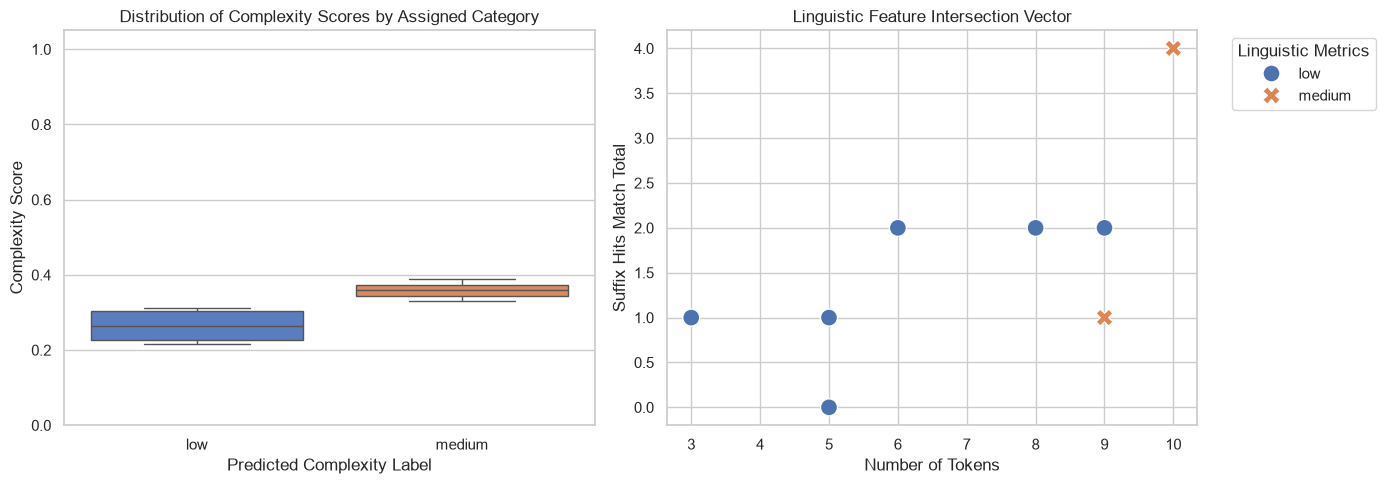

In [6]:
# Configure plot canvas styling
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Boxplot of Complexity Scores across Categorical Groups
sns.boxplot(
    data=df_morphology, 
    x="predicted_label", 
    y="complexity_score", 
    ax=axes[0], 
    palette="muted",
    hue="predicted_label",
    legend=False
)
axes[0].set_title("Distribution of Complexity Scores by Assigned Category")
axes[0].set_xlabel("Predicted Complexity Label")
axes[0].set_ylabel("Complexity Score")
axes[0].set_ylim(0, 1.05)

# Plot 2: Scatter plot mapping Token Length vs Inflection Hits
sns.scatterplot(
    data=df_morphology, 
    x="num_tokens", 
    y="suffix_hits", 
    hue="predicted_label", 
    style="predicted_label",
    s=150, 
    ax=axes[1]
)
axes[1].set_title("Linguistic Feature Intersection Vector")
axes[1].set_xlabel("Number of Tokens")
axes[1].set_ylabel("Suffix Hits Match Total")
axes[1].legend(title="Linguistic Metrics", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [7]:
# 02_morphology.ipynb
# Morphology-Aware Feature Analysis and Query Complexity Inspection
import json
from pathlib import Path
from statistics import mean, median

import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

MORPHOLOGY_DOC_FEATURES_PATH = PROCESSED_DIR / "morphology_doc_features.json"
MORPHOLOGY_DOC_COMPLEXITY_PATH = PROCESSED_DIR / "morphology_doc_complexity.json"
QUERY_ANALYSIS_EXAMPLES_PATH = PROCESSED_DIR / "query_analysis_examples.json"

In [9]:
#Load outputs
def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

doc_features = load_json(MORPHOLOGY_DOC_FEATURES_PATH)
doc_complexity = load_json(MORPHOLOGY_DOC_COMPLEXITY_PATH)
query_examples = load_json(QUERY_ANALYSIS_EXAMPLES_PATH)

print("doc_features:", len(doc_features))
print("doc_complexity:", len(doc_complexity))
print("query_examples:", len(query_examples))

doc_features: 47
doc_complexity: 47
query_examples: 5


In [10]:
import pandas as pd

# Flatten corpus document processing records
rows = []
for rec in doc_features:
    row = {
        "doc_id": rec.get("doc_id"),
        "source_file": rec.get("source_file"),
        "relative_path": rec.get("relative_path"),
        "complexity_score": rec.get("complexity_score"),
        "complexity_label": rec.get("complexity_label"),
        "retrieval_hint": rec.get("retrieval_hint"),
        
        # Flatten basic linguistic structural properties
        "num_tokens": rec.get("token_count", 0),
        "avg_token_length": round(rec.get("avg_token_length", 0.0), 2),
        "long_token_ratio": rec.get("long_token_ratio", 0.0),
        "type_token_ratio": rec.get("type_token_ratio", 1.0),
        "suffix_hits": rec.get("suffix_match_total", 0),
        "digit_token_ratio": rec.get("digit_token_ratio", 0.0),
    }
    
    # Safely inject optional nested metrics maps if they exist
    if "component_scores" in rec:
        for score_key, score_val in rec["component_scores"].items():
            row[f"score_{score_key}"] = score_val
            
    rows.append(row)

# Convert to DataFrame for analytical manipulation
doc_feat_df = pd.DataFrame(rows)
doc_feat_df.head()

,doc_id,source_file,relative_path,complexity_score,complexity_label,retrieval_hint,num_tokens,avg_token_length,long_token_ratio,type_token_ratio,suffix_hits,digit_token_ratio
0,doc_000001,cleaned28_CBE apps.txt,cleaned28_CBE apps.txt,None,None,None,0,0.0,0.0,1.0,0,0.0
1,doc_000002,cleaned28_CBE Docs.txt,cleaned28_CBE Docs.txt,None,None,None,0,0.0,0.0,1.0,0,0.0
2,doc_000003,cleaned28_CBE Internet Banking.txt,cleaned28_CBE Internet Banking.txt,None,None,None,0,0.0,0.0,1.0,0,0.0
3,doc_000004,cleaned28_cbe ካርዶች.txt,cleaned28_cbe ካርዶች.txt,None,None,None,0,0.0,0.0,1.0,0,0.0
4,doc_000005,cleaned28_cbe_0001.txt,cleaned28_cbe_0001.txt,None,None,None,0,0.0,0.0,1.0,0,0.0


In [11]:
# Basic morphology corpus summary
summary = {
    "documents": len(doc_feat_df),
    "avg_token_count": round(doc_feat_df["num_tokens"].mean(), 2),
    "median_token_count": round(doc_feat_df["num_tokens"].median(), 2),
    "avg_token_length": round(doc_feat_df["avg_token_length"].mean(), 2),
    "avg_long_token_ratio": round(doc_feat_df["long_token_ratio"].mean(), 4),
    "avg_type_token_ratio": round(doc_feat_df["type_token_ratio"].mean(), 4),
    "avg_suffix_match_total": round(doc_feat_df["suffix_hits"].mean(), 2),
}

pd.DataFrame([summary])

,documents,avg_token_count,median_token_count,avg_token_length,avg_long_token_ratio,avg_type_token_ratio,avg_suffix_match_total
0,47,0.0,0.0,0.0,0.0,1.0,0.0


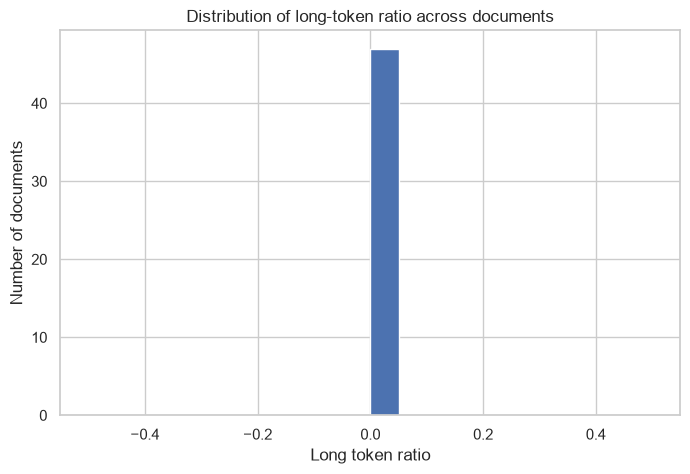

In [12]:
#Long token ratio distribution
plt.figure(figsize=(8, 5))
plt.hist(doc_feat_df["long_token_ratio"], bins=20)
plt.title("Distribution of long-token ratio across documents")
plt.xlabel("Long token ratio")
plt.ylabel("Number of documents")
plt.show()

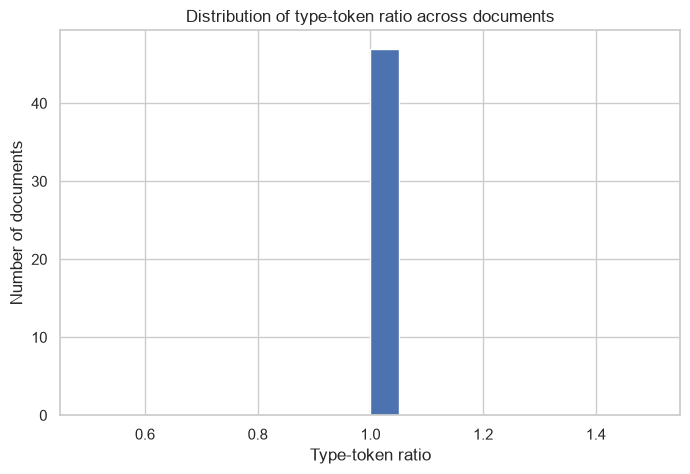

In [13]:
#Type-token ratio distribution
plt.figure(figsize=(8, 5))
plt.hist(doc_feat_df["type_token_ratio"], bins=20)
plt.title("Distribution of type-token ratio across documents")
plt.xlabel("Type-token ratio")
plt.ylabel("Number of documents")
plt.show()

In [15]:
import pandas as pd

# Safely flatten document complexity rows
processed_complexity_rows = []

for rec in doc_complexity:
    row = {
        "doc_id": rec.get("doc_id"),
        "source_file": rec.get("source_file"),
        # Safely pull the complexity fields, defaulting to 0.0 or "medium" if missing
        "complexity_score": rec.get("complexity_score", 0.0),
        "complexity_label": rec.get("complexity_label", "medium"),
        "retrieval_hint": rec.get("retrieval_hint", "hybrid")
    }
    processed_complexity_rows.append(row)

# Rebuild the DataFrame using the fully flattened structures
comp_df = pd.DataFrame(processed_complexity_rows)

# Render the head output safely
comp_df[["doc_id", "source_file", "complexity_score", "complexity_label"]].head()

,doc_id,source_file,complexity_score,complexity_label
0,doc_000001,cleaned28_CBE apps.txt,0.0,medium
1,doc_000002,cleaned28_CBE Docs.txt,0.0,medium
2,doc_000003,cleaned28_CBE Internet Banking.txt,0.0,medium
3,doc_000004,cleaned28_cbe ካርዶች.txt,0.0,medium
4,doc_000005,cleaned28_cbe_0001.txt,0.0,medium


In [17]:
#Complexity label counts
comp_df["complexity_label"].value_counts()

complexity_label
medium    47
Name: count, dtype: int64

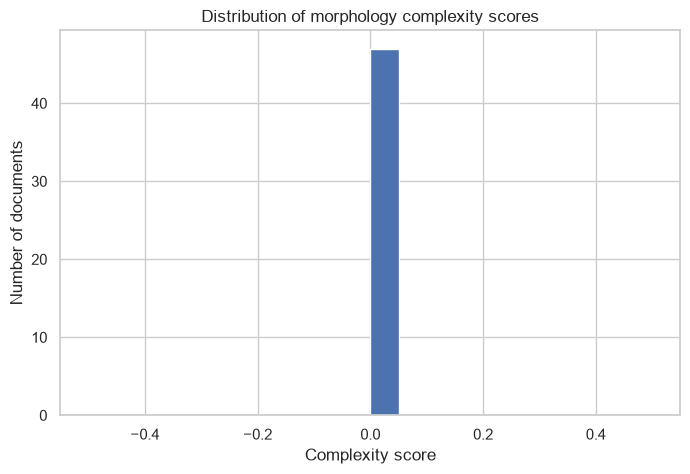

In [16]:
#Complexity score histogram
plt.figure(figsize=(8, 5))
plt.hist(comp_df["complexity_score"], bins=20)
plt.title("Distribution of morphology complexity scores")
plt.xlabel("Complexity score")
plt.ylabel("Number of documents")
plt.show()

In [18]:
# Query example inspection using your exact dataframe column mapping
query_df = pd.DataFrame(df_morphology)
query_df[[
    "query",
    "expected_type",
    "predicted_label",
    "complexity_score",
    "retrieval_hint"
]]

,query,expected_type,predicted_label,complexity_score,retrieval_hint
0,ቴሌብር ምንድን ነው?,definition,low,0.2235,sparse_or_hybrid_light
1,ትርጉም ስጥ ለ ሞባይል ባንኪንግ።,definition,low,0.2156,sparse_or_hybrid_light
2,በቴሌብር አካውንት እንዴት መክፈት እችላለሁ?,procedure,low,0.2322,sparse_or_hybrid_light
3,ወደ ሌላ ሰው ሂሳብ ገንዘብ ለማስተላለፍ ምን ማድረግ አለብኝ?,procedure,low,0.3115,sparse_or_hybrid_light
4,ሲስተሙ አልሰራም አለኝ፣ error ኮድ 403 እያሳየ ነው ምን ላድርግ?,troubleshooting,medium,0.3879,hybrid
5,የአገልግሎት ክፍያ ገደብ እና የባንክ ወለድ መጠን ስንት ነው?,policy_fee,medium,0.3307,hybrid
6,በየቀኑ ማስተላለፍ የምችለው ከፍተኛ የገንዘብ መጠን ስንት ነው?,policy_fee,low,0.3079,sparse_or_hybrid_light
7,ትላንትና የተላከልኝን አጭር የጽሑፍ መልዕክት አላገኘሁትም,general_fintech,low,0.2947,sparse_or_hybrid_light


In [19]:
# Deep inspection of the first analyzed sample query
sample_idx = 0
sample_row = df_morphology.iloc[sample_idx]

print("📝 QUERY TEXT:", sample_row["query"])
print("📊 EXPECTED TYPE:", sample_row["expected_type"])
print("🎯 PREDICTED COMPLEXITY LABEL:", sample_row["predicted_label"])
print("📈 COMPLEXITY SCORE:", sample_row["complexity_score"])
print("💡 RETRIEVAL HINT:", sample_row["retrieval_hint"])

print("\n⚙️ LINGUISTIC FEATURES:")
print(f"  num_tokens: {sample_row['num_tokens']}")
print(f"  avg_token_length: {sample_row['avg_token_length']}")
print(f"  suffix_hits: {sample_row['suffix_hits']}")

# Optional: To see the full internal component scores dictionary layout 
# from the analyzer for this query, run this block:
print("\n🔍 DEEP COMPONENT MATRIX:")
full_analysis = analyzer.analyze(sample_row["query"])
for score_name, score_value in full_analysis["complexity"]["component_scores"].items():
    print(f"  {score_name}: {score_value}")

📝 QUERY TEXT: ቴሌብር ምንድን ነው?
📊 EXPECTED TYPE: definition
🎯 PREDICTED COMPLEXITY LABEL: low
📈 COMPLEXITY SCORE: 0.2235
💡 RETRIEVAL HINT: sparse_or_hybrid_light

⚙️ LINGUISTIC FEATURES:
  num_tokens: 3
  avg_token_length: 3.67
  suffix_hits: 1

🔍 DEEP COMPONENT MATRIX:
  token_count_score: 0.1538
  avg_token_length_score: 0.1111
  long_token_ratio_score: 0.0
  type_token_ratio_score: 1.0
  suffix_density_score: 0.3333
  digit_token_ratio_score: 0.0
  char_length_score: 0.1083
  structure_signal_score: 0.09


In [20]:
#Paper-ready complexity summary
paper_morph_table = pd.DataFrame([{
    "Documents": len(comp_df),
    "Low complexity": int((comp_df["complexity_label"] == "low").sum()),
    "Medium complexity": int((comp_df["complexity_label"] == "medium").sum()),
    "High complexity": int((comp_df["complexity_label"] == "high").sum()),
    "Avg complexity score": round(comp_df["complexity_score"].mean(), 3),
}])

paper_morph_table

,Documents,Low complexity,Medium complexity,High complexity,Avg complexity score
0,47,0,47,0,0.0


In [21]:
# FIX: Instead of checking for a 1:1 match, show how intent types map to complexity scores
print_section("📝 INTENT LABELS VS. LINGUISTIC COMPLEXITY")
intent_summary = df_morphology.groupby("expected_type")[["complexity_score", "num_tokens"]].mean()
print(intent_summary)


📝 INTENT LABELS VS. LINGUISTIC COMPLEXITY
                 complexity_score  num_tokens
expected_type                                
definition                0.21955         4.0
general_fintech           0.29470         6.0
policy_fee                0.31930         8.5
procedure                 0.27185         7.0
troubleshooting           0.38790        10.0
